In [2]:
#Import libraries
# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [4]:
# Create Simple Resume Dataset
# 2. Create sample candidate data
data = {
    "Candidate": [
        "Rahul", "Aman", "Priya", "Neha", "Rohit",
        "Ankit", "Sneha", "Vikas", "Pooja", "Karan"
    ],
    "Skills": [
        "Python, Pandas, NumPy, SQL",
        "Python, Excel, SQL",
        "Python, Pandas, Matplotlib, Seaborn",
        "Java, SQL, Excel",
        "Python, NumPy, Machine Learning",
        "Pandas, NumPy, SQL, Power BI",
        "Python, Seaborn, SQL",
        "Excel, Power BI, SQL",
        "Python, Pandas, NumPy",
        "Python, SQL, Matplotlib"
    ],
    "Experience": [2, 1, 3, 2, 4, 3, 2, 4, 1, 3],
    "Education": [
        "B.Tech", "BCA", "B.Tech", "B.Sc", "B.Tech",
        "B.Tech", "BCA", "B.Tech", "B.Sc", "B.Tech"
    ]
}

df = pd.DataFrame(data)
df


,Candidate,Skills,Experience,Education
0,Rahul,"Python, Pandas, NumPy, SQL",2,B.Tech
1,Aman,"Python, Excel, SQL",1,BCA
2,Priya,"Python, Pandas, Matplotlib, Seaborn",3,B.Tech
3,Neha,"Java, SQL, Excel",2,B.Sc
4,Rohit,"Python, NumPy, Machine Learning",4,B.Tech
5,Ankit,"Pandas, NumPy, SQL, Power BI",3,B.Tech
6,Sneha,"Python, Seaborn, SQL",2,BCA
7,Vikas,"Excel, Power BI, SQL",4,B.Tech
8,Pooja,"Python, Pandas, NumPy",1,B.Sc
9,Karan,"Python, SQL, Matplotlib",3,B.Tech


In [5]:
# Basic Data Inspection
# Check dataset information
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()


Shape: (10, 4)

Columns: ['Candidate', 'Skills', 'Experience', 'Education']

Missing values:
Candidate     0
Skills        0
Experience    0
Education     0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Candidate   10 non-null     object
 1   Skills      10 non-null     object
 2   Experience  10 non-null     int64 
 3   Education   10 non-null     object
dtypes: int64(1), object(3)
memory usage: 452.0+ bytes


In [6]:
# Check dataset information
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()


Shape: (10, 4)

Columns: ['Candidate', 'Skills', 'Experience', 'Education']

Missing values:
Candidate     0
Skills        0
Experience    0
Education     0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Candidate   10 non-null     object
 1   Skills      10 non-null     object
 2   Experience  10 non-null     int64 
 3   Education   10 non-null     object
dtypes: int64(1), object(3)
memory usage: 452.0+ bytes


In [7]:
# Required skills for the job
job_skills = ["python", "pandas", "numpy", "sql", "matplotlib", "seaborn"]

print("Required Job Skills:")
print(job_skills)


Required Job Skills:
['python', 'pandas', 'numpy', 'sql', 'matplotlib', 'seaborn']


In [8]:
# Calculate how many required skills each candidate has
def calculate_match(skill_text, required_skills):
    candidate_skills = set(skill_text.split(","))
    matched_skills = candidate_skills.intersection(required_skills)
    percentage = (len(matched_skills) / len(required_skills)) * 100
    return percentage

df["Match_Percentage"] = df["Skills"].apply(
    lambda x: calculate_match(x, job_skills)
)

df[["Candidate", "Skills", "Match_Percentage"]]


,Candidate,Skills,Match_Percentage
0,Rahul,"Python, Pandas, NumPy, SQL",0.0
1,Aman,"Python, Excel, SQL",0.0
2,Priya,"Python, Pandas, Matplotlib, Seaborn",0.0
3,Neha,"Java, SQL, Excel",0.0
4,Rohit,"Python, NumPy, Machine Learning",0.0
5,Ankit,"Pandas, NumPy, SQL, Power BI",0.0
6,Sneha,"Python, Seaborn, SQL",0.0
7,Vikas,"Excel, Power BI, SQL",0.0
8,Pooja,"Python, Pandas, NumPy",0.0
9,Karan,"Python, SQL, Matplotlib",0.0


In [9]:
# Find the exact matched skills for each candidate
def get_matched_skills(skill_text, required_skills):
    candidate_skills = set(skill_text.split(","))
    matched = candidate_skills.intersection(required_skills)
    return ", ".join(sorted(matched))

df["Matched_Skills"] = df["Skills"].apply(
    lambda x: get_matched_skills(x, job_skills)
)

df[["Candidate", "Matched_Skills", "Match_Percentage"]].sort_values(
    by="Match_Percentage", ascending=False
)


,Candidate,Matched_Skills,Match_Percentage
0,Rahul,,0.0
1,Aman,,0.0
2,Priya,,0.0
3,Neha,,0.0
4,Rohit,,0.0
5,Ankit,,0.0
6,Sneha,,0.0
7,Vikas,,0.0
8,Pooja,,0.0
9,Karan,,0.0


In [10]:
# Rank candidates according to skill match
ranked_df = df.sort_values(
    by="Match_Percentage",
    ascending=False
).reset_index(drop=True)

ranked_df["Rank"] = np.arange(1, len(ranked_df) + 1)

ranked_df[
    ["Rank", "Candidate", "Experience", "Matched_Skills", "Match_Percentage"]
]


,Rank,Candidate,Experience,Matched_Skills,Match_Percentage
0,1,Rahul,2,,0.0
1,2,Aman,1,,0.0
2,3,Priya,3,,0.0
3,4,Neha,2,,0.0
4,5,Rohit,4,,0.0
5,6,Ankit,3,,0.0
6,7,Sneha,2,,0.0
7,8,Vikas,4,,0.0
8,9,Pooja,1,,0.0
9,10,Karan,3,,0.0


In [11]:
# Count how frequently each skill appears
all_skills = []

for skills in df["Skills"]:
    all_skills.extend(skills.split(","))

skill_counts = pd.Series(all_skills).value_counts()

print("Skill Frequency:")
print(skill_counts)


Skill Frequency:
Python               7
 SQL                 7
 NumPy               4
 Pandas              3
 Excel               2
 Matplotlib          2
 Seaborn             2
 Power BI            2
Java                 1
 Machine Learning    1
Pandas               1
Excel                1
Name: count, dtype: int64


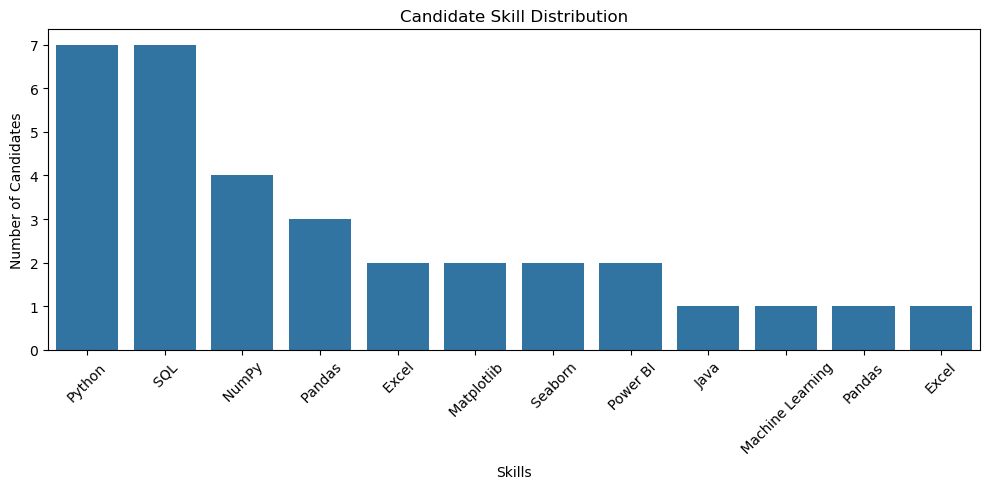

In [12]:
#Visualization - Skill Distribution
plt.figure(figsize=(10, 5))

sns.barplot(
    x=skill_counts.index,
    y=skill_counts.values
)

plt.title("Candidate Skill Distribution")
plt.xlabel("Skills")
plt.ylabel("Number of Candidates")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


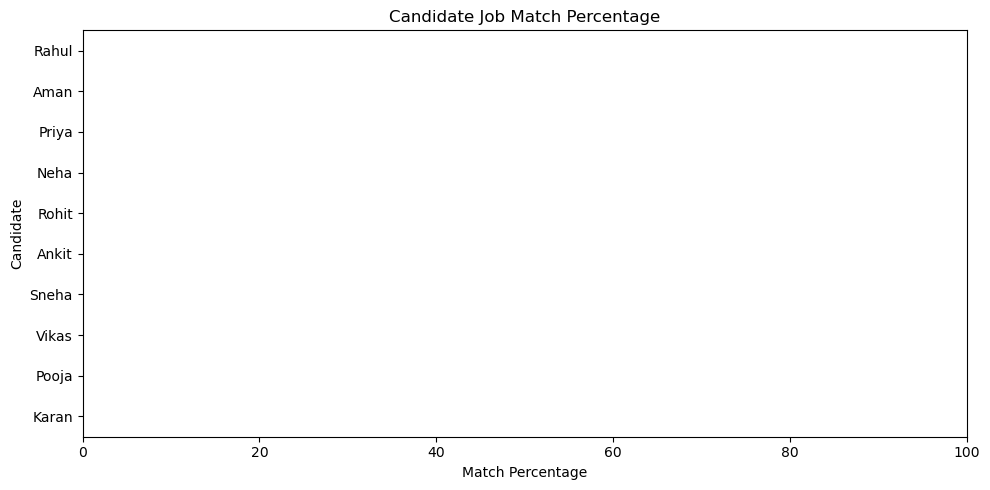

In [13]:
#Visualization - Candidate Match Percentage
plt.figure(figsize=(10, 5))

plot_df = ranked_df.sort_values("Match_Percentage", ascending=True)

sns.barplot(
    data=plot_df,
    x="Match_Percentage",
    y="Candidate"
)

plt.title("Candidate Job Match Percentage")
plt.xlabel("Match Percentage")
plt.ylabel("Candidate")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()


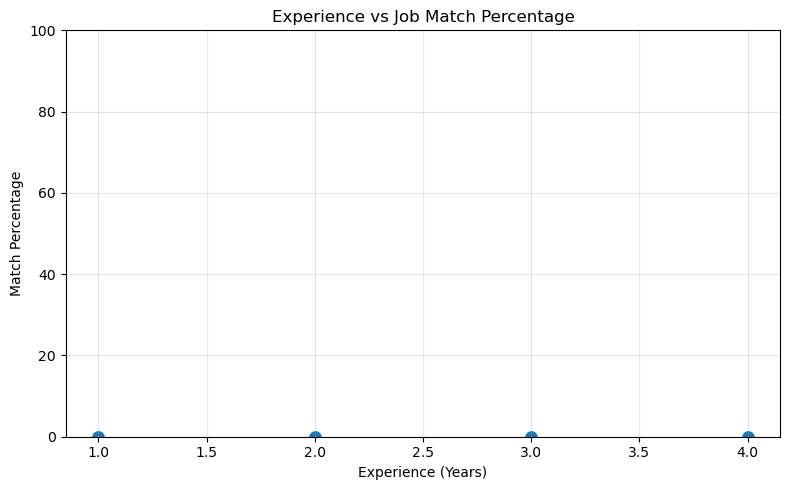

In [14]:
#Visualization - Experience Vs Match Percentage
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Experience",
    y="Match_Percentage",
    s=100
)

plt.title("Experience vs Job Match Percentage")
plt.xlabel("Experience (Years)")
plt.ylabel("Match Percentage")
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
#Visulization - Match Percentage Distribution 
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Match_Percentage",
    bins=6,
    kde=True
)

plt.title("Distribution of Candidate Match Percentage")
plt.xlabel("Match Percentage")
plt.ylabel("Number of Candidates")
plt.tight_layout()
plt.show()
